# Phase 3: Kalman filter decoder

**Goal:** decode hand velocity with a Kalman filter, a classic brain-computer interface decoder, and compare it with the Phase 2 ridge decoder on exactly the same held-out trials and time bins.

**Steps**
1. Load the data and reuse the Phase 2 split (the same 80 training and 20 test trials).
2. Choose the Kalman filter's two settings (neural lag and spike window) by cross-validation on the training trials.
3. Fit the Kalman filter and decode the test trials.
4. Refit the ridge baseline, this time also testing longer spike histories (300 and 400 ms), as Phase 2 suggested.
5. Compare the two decoders on identical test bins, and plot their predictions.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score
from sklearn.model_selection import KFold

sys.path.insert(0, os.path.abspath(".."))
from src.data import BIN_MS, load_dataset, get_trials, build_features, build_sequences
from src.decoders import KalmanDecoder, fit_ridge

DATA_PATH = "../data/000140/sub-Jenkins/"
LAGS_MS = [0, 40, 80, 120, 160]          # how far back the neural data is taken from
WINDOWS = [1, 3, 5, 7]                    # spike-count window, in 20 ms bins (20, 60, 100, 140 ms)
RIDGE_HISTORIES_MS = [200, 300, 400]      # ridge spike history to compare
MARGIN_MS = max(RIDGE_HISTORIES_MS)       # extra data kept before each trial window
os.makedirs("../figures", exist_ok=True)

## 1. Load the data and reuse the Phase 2 split

The split uses the same random seed as Phase 2, so the 20 test trials are identical and the results can be compared directly. More data is kept before each trial window this time (400 ms) to allow longer spike histories.

In [2]:
dataset = load_dataset(DATA_PATH)
trials = get_trials(dataset, history_ms=MARGIN_MS)

trial_ids = np.unique(trials["trial_id"])
rng = np.random.default_rng(0)                          # same seed as Phase 2
test_ids = rng.choice(trial_ids, size=20, replace=False)
train_ids = np.setdiff1d(trial_ids, test_ids)
print(len(train_ids), "training trials |", len(test_ids), "test trials")
print("test trials:", sorted(test_ids.tolist()))

80 training trials | 20 test trials
test trials: [1, 3, 6, 15, 22, 26, 42, 46, 52, 53, 55, 57, 59, 61, 68, 70, 73, 83, 92, 93]


## 2. How a Kalman filter decodes

A Kalman filter keeps a running estimate of the hand's **state**: position (x, y), velocity (x, y), and a constant. It uses two models, both fit by least squares on the training trials:

- **Movement model:** how the state usually changes from one 20 ms step to the next. Hands move smoothly, so the next velocity is close to the current one.
- **Neural model:** what spike counts each state tends to produce. This is the directional tuning seen in Phase 1.

At every step the filter **predicts** the new state from the movement model, then **corrects** the prediction using the new spikes. It weights each source by how reliable it has been in training. The movement model smooths out spike noise, which is the weakness Phase 2 revealed in ridge regression.

**Two settings to choose:**
- **Lag:** neurons fire before the movement they drive, so the observation at each step uses spikes from `lag` ms earlier.
- **Window:** spike counts are summed over the last 1, 3, 5, or 7 bins (20 to 140 ms), trading noise against timing detail.

Both are chosen by 5-fold cross-validation on the 80 training trials only. Each fold holds out whole trials.

In [3]:
seq_cache = {}
def get_seqs(lag_ms, window_bins):
    # Sequences for one setting, keyed by trial id (cached so each is built once)
    key = (lag_ms, window_bins)
    if key not in seq_cache:
        seq_cache[key] = {s["trial_id"]: s for s in build_sequences(trials, lag_ms, window_bins)}
    return seq_cache[key]

def kalman_velocity_r2(model, seqs, ids):
    # R² for x and y velocity, pooled over the given trials
    true, pred = [], []
    for tid in ids:
        s = seqs[tid]
        est = model.predict(s["Z"])
        known = ~np.isnan(s["X"]).any(axis=1)
        true.append(s["X"][known, 2:4]); pred.append(est[known, 2:4])
    return r2_score(np.vstack(true), np.vstack(pred), multioutput="raw_values")

folds = list(KFold(n_splits=5, shuffle=True, random_state=0).split(train_ids))
rows = []
for lag in LAGS_MS:
    for w in WINDOWS:
        seqs = get_seqs(lag, w)
        scores = [kalman_velocity_r2(KalmanDecoder().fit([seqs[i] for i in train_ids[tr]]), seqs, train_ids[va]).mean()
                  for tr, va in folds]
        rows.append({"lag_ms": lag, "window_ms": w * BIN_MS, "cv_r2": np.mean(scores)})
kalman_cv = pd.DataFrame(rows)
print("Cross-validated R² (rows: lag in ms, columns: spike window in ms)")
print(kalman_cv.pivot(index="lag_ms", columns="window_ms", values="cv_r2").round(3))

best_k = kalman_cv.loc[kalman_cv["cv_r2"].idxmax()]
LAG, WIN = int(best_k["lag_ms"]), int(best_k["window_ms"]) // BIN_MS
print(f"\nChosen: lag = {LAG} ms, window = {WIN * BIN_MS} ms (cross-validated R² = {best_k['cv_r2']:.3f})")
if LAG == max(LAGS_MS) or WIN == max(WINDOWS):
    print("  note: a chosen setting is at the top of the range tried; larger values might help")

Cross-validated R² (rows: lag in ms, columns: spike window in ms)
window_ms    20     60     100    140
lag_ms                               
0          0.317  0.337  0.318  0.315
40         0.355  0.375  0.371  0.374
80         0.403  0.422  0.413  0.411
120        0.434  0.442  0.437  0.422
160        0.442  0.457  0.431  0.390

Chosen: lag = 160 ms, window = 60 ms (cross-validated R² = 0.457)
  note: a chosen setting is at the top of the range tried; larger values might help


## 3. Fit the Kalman filter and decode the test trials

In [4]:
seqs = get_seqs(LAG, WIN)
kalman = KalmanDecoder().fit([seqs[i] for i in train_ids])

kal_parts = []
for tid in test_ids:
    est = kalman.predict(seqs[tid]["Z"])
    kal_parts.append(pd.DataFrame({"trial": tid, "t": seqs[tid]["t"], "kal_x": est[:, 2], "kal_y": est[:, 3]}))
kal_df = pd.concat(kal_parts, ignore_index=True)
print("decoded", len(kal_df), "test bins")

decoded 700 test bins


## 4. Ridge baseline, now with longer histories

Phase 2's ridge decoder was still improving at 200 ms of spike history, the longest it tried. Here it also tries 300 and 400 ms. The history is chosen by cross-validated R² on the training trials, as before. This cell takes several minutes because the longest history has about 3,000 input columns.

In [5]:
X_all, y, groups, t_ms = build_features(trials, n_lags=max(RIDGE_HISTORIES_MS) // BIN_MS)
n_neurons = trials["spikes"].shape[1]
train = np.isin(groups, train_ids)
test = np.isin(groups, test_ids)

ridge_runs = []
for h in RIDGE_HISTORIES_MS:
    cols = n_neurons * (h // BIN_MS + 1)                # current bin + h ms of earlier bins
    search = fit_ridge(X_all[train, :cols], y[train], groups[train])
    ridge_runs.append({"history_ms": h, "alpha": search.best_params_["ridge__alpha"],
                       "cv_r2": search.best_score_, "search": search, "cols": cols})
print(pd.DataFrame(ridge_runs)[["history_ms", "alpha", "cv_r2"]].round(3).to_string(index=False))

best_r = max(ridge_runs, key=lambda r: r["cv_r2"])
print(f"\nChosen ridge history: {best_r['history_ms']} ms")
if best_r["history_ms"] == max(RIDGE_HISTORIES_MS):
    print("  note: the longest history tried scored best")
ridge_pred = best_r["search"].predict(X_all[test, :best_r["cols"]])

 history_ms    alpha  cv_r2
        200 3162.278  0.574
        300 3162.278  0.631
        400 3162.278  0.649

Chosen ridge history: 400 ms
  note: the longest history tried scored best


## 5. Compare on identical test bins

Both decoders are scored on exactly the same test-trial time bins, so the comparison is fair.

In [6]:
ridge_df = pd.DataFrame({"trial": groups[test], "t": t_ms[test],
                         "true_x": y[test, 0], "true_y": y[test, 1],
                         "ridge_x": ridge_pred[:, 0], "ridge_y": ridge_pred[:, 1]})
both = ridge_df.merge(kal_df, on=["trial", "t"], how="inner").sort_values(["trial", "t"]).reset_index(drop=True)

def r2_row(name, px, py):
    rx, ry = r2_score(both["true_x"], both[px]), r2_score(both["true_y"], both[py])
    return {"decoder": name, "R² x": rx, "R² y": ry, "R² mean": (rx + ry) / 2}

comparison = pd.DataFrame([
    r2_row(f"Ridge ({best_r['history_ms']} ms history)", "ridge_x", "ridge_y"),
    r2_row(f"Kalman filter (lag {LAG} ms, window {WIN * BIN_MS} ms)", "kal_x", "kal_y"),
])
print(f"{len(both)} test bins from {both['trial'].nunique()} held-out trials\n")
print(comparison.round(3).to_string(index=False))

700 test bins from 20 held-out trials

                                 decoder  R² x  R² y  R² mean
                  Ridge (400 ms history) 0.686 0.525    0.606
Kalman filter (lag 160 ms, window 60 ms) 0.506 0.294    0.400


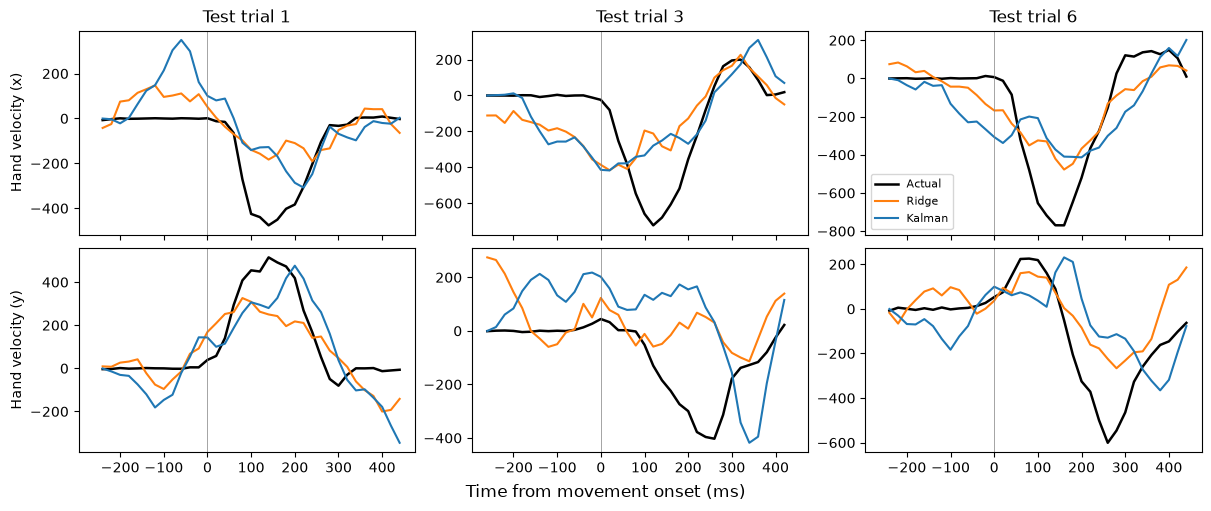

In [7]:
# Figure 8: decoded vs. actual velocity on three test trials, ridge and Kalman
show_ids = sorted(both["trial"].unique())[:3]
fig, axes = plt.subplots(2, 3, figsize=(12, 5), sharex=True, constrained_layout=True)
for col, tid in enumerate(show_ids):
    d = both[both["trial"] == tid]
    for row, k in enumerate(["x", "y"]):
        ax = axes[row, col]
        ax.plot(d["t"], d[f"true_{k}"], color="black", lw=1.8, label="Actual")
        ax.plot(d["t"], d[f"ridge_{k}"], color="tab:orange", label="Ridge")
        ax.plot(d["t"], d[f"kal_{k}"], color="tab:blue", label="Kalman")
        ax.axvline(0, color="gray", lw=0.5)
        if col == 0:
            ax.set_ylabel(f"Hand velocity ({k})")
        if row == 0:
            ax.set_title(f"Test trial {tid}")
axes[0, -1].legend(fontsize=8)
fig.supxlabel("Time from movement onset (ms)")
plt.savefig("../figures/08_kalman_vs_ridge_velocity.png", dpi=150, bbox_inches="tight")

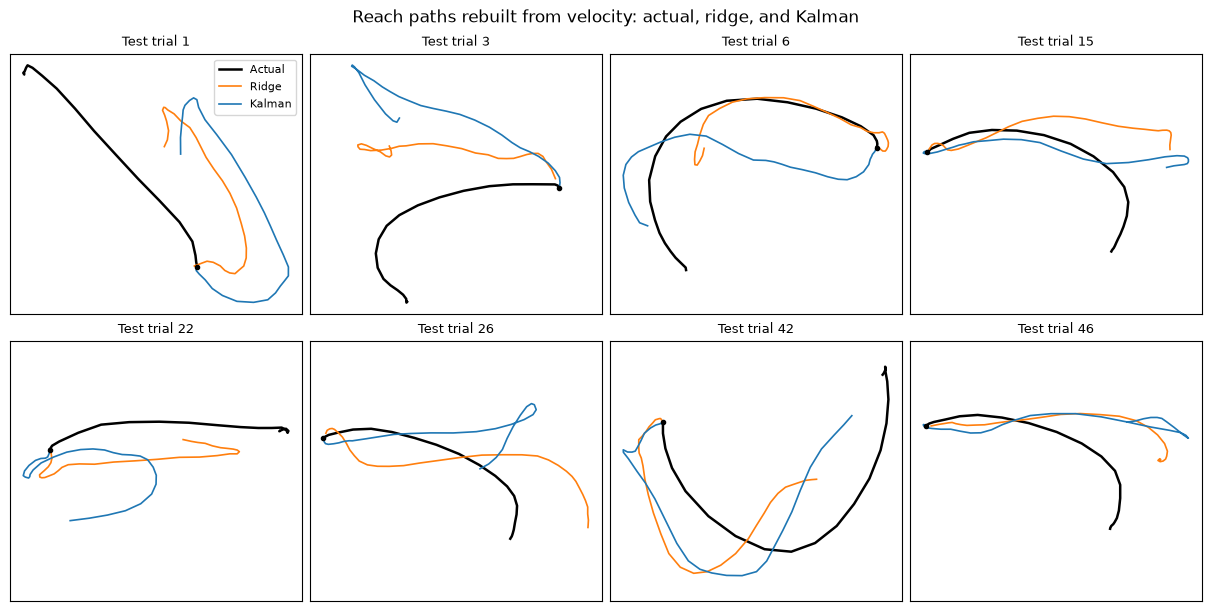

In [8]:
# Figure 9: reach paths rebuilt by adding up velocity over time
dt = BIN_MS / 1000
path_ids = sorted(both["trial"].unique())[:8]
fig, axes = plt.subplots(2, 4, figsize=(12, 6), constrained_layout=True)
for ax, tid in zip(axes.flat, path_ids):
    d = both[both["trial"] == tid]
    for name, cx, cy, color, lw in [("Actual", "true_x", "true_y", "black", 1.8),
                                    ("Ridge", "ridge_x", "ridge_y", "tab:orange", 1.2),
                                    ("Kalman", "kal_x", "kal_y", "tab:blue", 1.2)]:
        ax.plot(np.cumsum(d[cx]) * dt, np.cumsum(d[cy]) * dt, color=color, lw=lw, label=name)
    ax.plot(0, 0, "o", color="black", ms=3)
    ax.set_title(f"Test trial {tid}", fontsize=9)
    ax.set_aspect("equal", adjustable="datalim")
    ax.set_xticks([]); ax.set_yticks([])
axes.flat[0].legend(fontsize=8)
fig.suptitle("Reach paths rebuilt from velocity: actual, ridge, and Kalman")
plt.savefig("../figures/09_kalman_vs_ridge_paths.png", dpi=150, bbox_inches="tight")

## Results to record

Copy these lines into the README.

**What to look for:** whether the Kalman filter's velocity traces are smoother and closer to the actual peaks than ridge's, and whether its rebuilt paths drift less. Kalman filters often help most where ridge was noisy. Ridge, though, sees a long spike history directly, so either decoder can come out ahead on this dataset.

**Next (Phase 4):** a recurrent neural network, which can learn its own movement dynamics and nonlinear tuning from the data.

In [9]:
k = comparison.iloc[1]; r = comparison.iloc[0]
print(f"Kalman filter (lag {LAG} ms, {WIN * BIN_MS} ms spike window): held-out R² = {k['R² mean']:.2f} "
      f"(x = {k['R² x']:.2f}, y = {k['R² y']:.2f})")
print(f"Ridge ({best_r['history_ms']} ms history, same bins): held-out R² = {r['R² mean']:.2f} "
      f"(x = {r['R² x']:.2f}, y = {r['R² y']:.2f})")

Kalman filter (lag 160 ms, 60 ms spike window): held-out R² = 0.40 (x = 0.51, y = 0.29)
Ridge (400 ms history, same bins): held-out R² = 0.61 (x = 0.69, y = 0.53)
